导包

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

读入数据

In [ ]:
df = pd.read_csv('C:\\Users\\Zzq\\Desktop\\Netflix_Customer_Churn_Analysis\\data\\netflix_customer_churn.csv')
df.head(5)

了解数据的基础信息:
Data columns (total 14 columns):
Num  Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str  

数值字段的描述性统计:
	       age	    watch_hours	last_login_days	 monthly_fee  churned	number_of_profiles	avg_watch_time_per_day
count	5000.000000	5000.000000	 5000.000000	 5000.000000 5000.000000	5000.000000			5000.000000
mean	43.847400	11.649450	 30.089800	     13.683400	 0.503000		3.024400			0.874800
std	    15.501128	12.014654	 17.536078	     3.692062	 0.500041		1.415841			2.619824
min	    18.000000	0.010000	 0.000000		 8.990000	 0.000000		1.000000			0.000000
25%	    30.000000	3.337500	 15.000000		 8.990000	 0.000000		2.000000			0.110000
50%	    44.000000	8.000000	 30.000000		 13.990000	 1.000000		3.000000			0.290000
75%	    58.000000	16.030000	 45.000000		 17.990000	 1.000000		4.000000			0.720000
max	    70.000000	110.400000	 60.000000		 17.990000	 1.000000		5.000000			98.420000

	通过上述两步对数据有了大概了解,能够提前思考接下来的数据清洗部分

In [ ]:
print(df.info())
print(df.describe())

了解表格构成以及缺失值情况:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0

In [ ]:
print(df.isnull().sum())

缺失情况了解后,用箱线图对异常值进行并将customer_id这一列删掉(对后续操作无作用)

In [ ]:
df = df.drop('customer_id', axis=1)

In [18]:
df.head()

,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


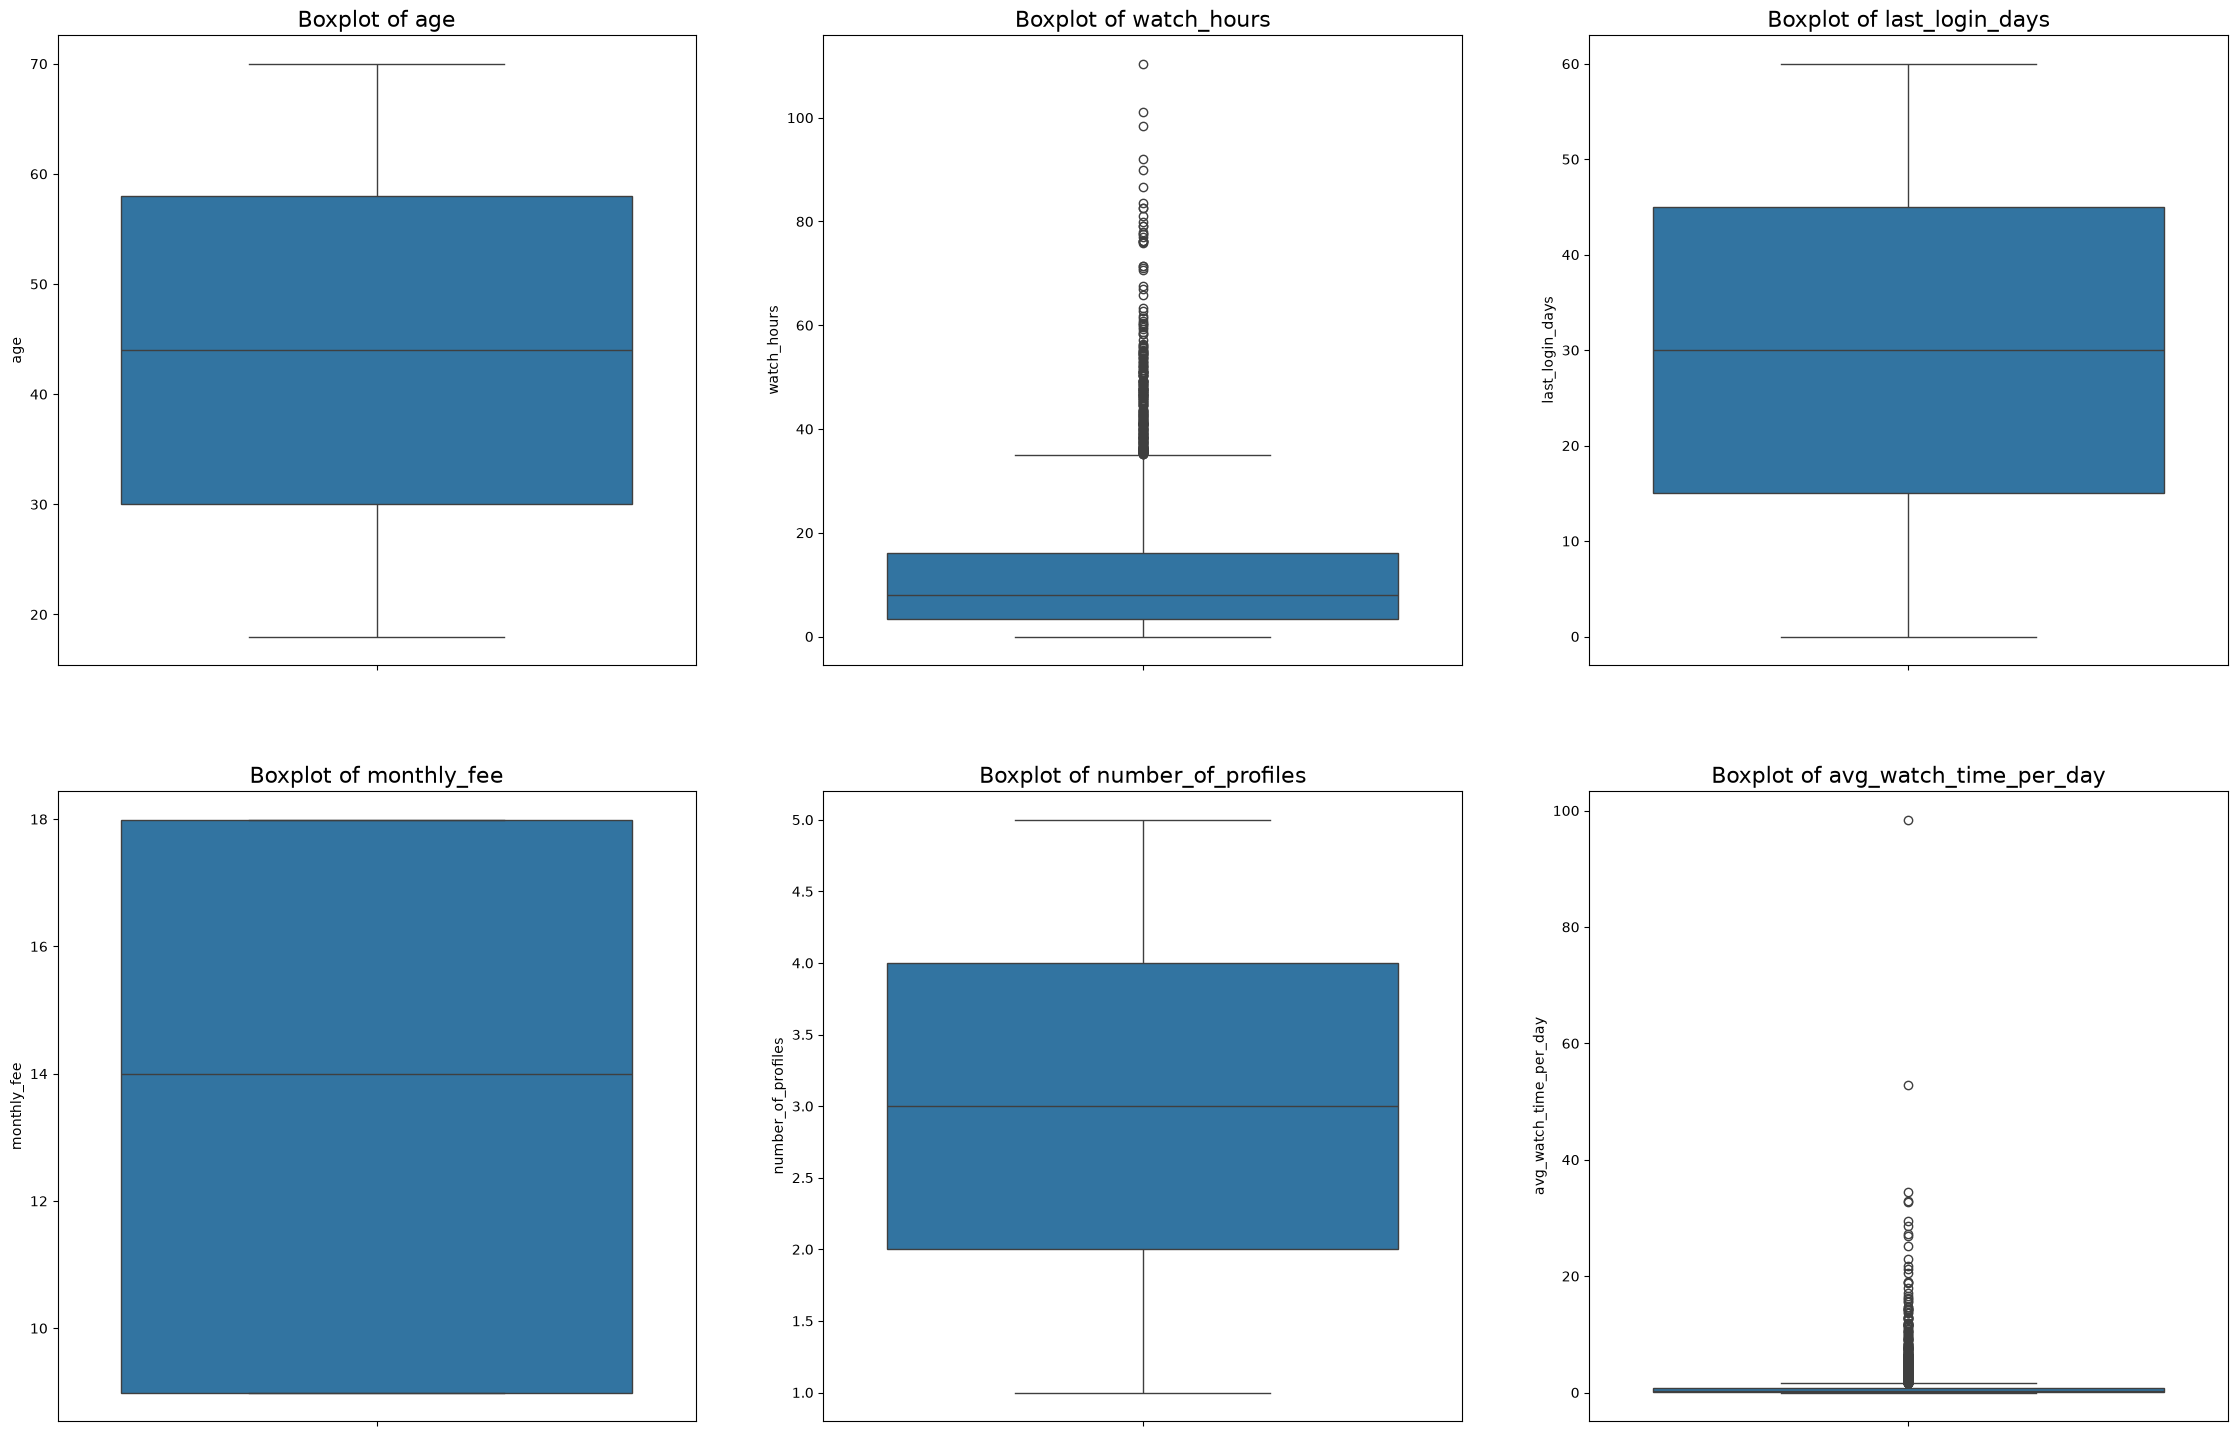

In [37]:
numberical_columns = ['age', 'watch_hours', 'last_login_days', 
                      'monthly_fee', 'number_of_profiles','avg_watch_time_per_day']
fig , axes = plt.subplots(2,3, figsize = (28,18))
axes = axes.flatten()
for i, col in enumerate(numberical_columns):
    # sns.histplot(df[col], ax=axes[i], kde=True)
    sns.boxplot(y=df[col], ax=axes[i],data = df)
    axes[i].set_title(f'Boxplot of {col}', fontsize=16)

#替换的六张图把numerical_columns的第六个列名字删掉加上以下代码

# ax_hist = axes[-1]
# x_data = df['avg_watch_time_per_day']
# sns.histplot(x = x_data,ax= ax_hist,kde = True)
# axes[-1].set_title('Histogram of Average Watch Time', fontsize=16)
# plt.tight_layout()
# plt.show()


In [39]:
print('subscription_type列的唯一值:', list(df['subscription_type'].unique()))
print('region列的唯一值:', list(df['region'].unique()))
print('device列的唯一值:', list(df['device'].unique()))
print('payment_method列的唯一值:', list(df['payment_method'].unique()))
print('favorite_genre列的唯一值:', list(df['favorite_genre'].unique()))

subscription_type列的唯一值: ['Basic', 'Standard', 'Premium']
region列的唯一值: ['Africa', 'Europe', 'Asia', 'Oceania', 'South America', 'North America']
device列的唯一值: ['TV', 'Mobile', 'Laptop', 'Desktop', 'Tablet']
payment_method列的唯一值: ['Gift Card', 'Crypto', 'Debit Card', 'PayPal', 'Credit Card']
favorite_genre列的唯一值: ['Action', 'Sci-Fi', 'Drama', 'Horror', 'Romance', 'Comedy', 'Documentary']


建立模型采用二分类模型

In [ ]:
import sys
print(sys.executable)   #确定环境路径
#c:\Users\Zzq\.venv\Scripts\python.exe -m pip install scikit-learn(终端下载scikit-learn)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve